# ELEC 576 / COMP 576 — Assignment 2
**Name:** YinHsuan Hsu   **NetID:** yh207   **Date:** 10/28/2026

**Document structure**
- **Section A — Problem 1:** Visualizing a CNN with CIFAR10 (LeNet5, hyperparameter search, filter/activation visualization)
- **Section B — Problem 2:** Summary of "Visualizing and Understanding Convolutional Networks" (Zeiler & Fergus) + optional occlusion-sensitivity visualization
- **Section C — Problem 3:** Build and train an RNN / LSTM / GRU on MNIST, plus comparison with the Assignment 1 CNN

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter
from datetime import datetime
from pathlib import Path
import matplotlib.pyplot as plt

# hyperparameters
batch_size = 128
epochs = 10
lr = 0.001
try_cuda = True
seed = 1000
num_classes = 10
logging_interval = 300
grayscale = True

# TensorBoard logging dir
datetime_str = datetime.now().strftime('%b%d_%H-%M-%S')
runs_dir = Path("./runs/")
runs_dir.mkdir(exist_ok=True)
logging_dir = runs_dir / datetime_str
logging_dir.mkdir(exist_ok=True)
writer = SummaryWriter(log_dir=str(logging_dir.absolute()))
print("TensorBoard log dir:", logging_dir.absolute())

# CUDA
if torch.cuda.is_available() and try_cuda:
    cuda = True
    torch.cuda.manual_seed(seed)
else:
    cuda = False
    torch.manual_seed(seed)
print("cuda =", cuda)

TensorBoard log dir: d:\School\Code\Rice\COMP_576\Assignment\A2\runs\Oct28_16-13-39
cuda = True


In [2]:
# CIFAR10 folder is already grayscale 28x28, split into Train/0..9 and Test/0..9
# ImageFolder assigns label by sorted subfolder name: '0' -> 0, ..., '9' -> 9
# (matches the original CIFAR10 class order: airplane=0, automobile=1, ...)

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),   # safe no-op if already 'L'
    transforms.Resize((28, 28)),                   # safe no-op if already 28x28
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.ImageFolder(
    root='./CIFAR10/Train', transform=transform
)
test_dataset = datasets.ImageFolder(
    root='./CIFAR10/Test', transform=transform
)

print("Classes:", train_dataset.classes)
print("train size:", len(train_dataset), "test size:", len(test_dataset))

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False, num_workers=0
)

def check_data_loader_dim(loader):
    for images, labels in loader:
        print('Image batch dimensions:', images.shape)
        print('Image label dimensions:', labels.shape)
        break

check_data_loader_dim(train_loader)
check_data_loader_dim(test_loader)

Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
train size: 10000 test size: 1000
Image batch dimensions: torch.Size([128, 1, 28, 28])
Image label dimensions: torch.Size([128])
Image batch dimensions: torch.Size([128, 1, 28, 28])
Image label dimensions: torch.Size([128])


In [3]:
# One-hot encoding demonstration
images, labels = next(iter(train_loader))
one_hot = torch.zeros(labels.size(0), num_classes)
one_hot.scatter_(1, labels.unsqueeze(1), 1.0)
print('labels[:5]  =', labels[:5])
print('one_hot[:2] =\n', one_hot[:2])

labels[:5]  = tensor([4, 7, 9, 1, 2])
one_hot[:2] =
 tensor([[0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 1., 0., 0.]])


In [4]:
layer_1_n_filters = 6
layer_2_n_filters = 16
fc_1_n_nodes = 120
fc_2_n_nodes = 84
kernel_size = 5
verbose = False

# 28x28 -> conv(pad=2) 28x28 -> pool 14x14
# -> conv 10x10 -> pool 5x5
final_length = 5

if verbose:
    print(f"final_length = {final_length}")

class LeNet5(nn.Module):
    def __init__(self, num_classes, grayscale=False):
        super(LeNet5, self).__init__()
        self.grayscale = grayscale
        self.num_classes = num_classes
        in_channels = 1 if self.grayscale else 3

        self.features = nn.Sequential(
            nn.Conv2d(in_channels, layer_1_n_filters,
                      kernel_size=kernel_size, padding=2),
            nn.Tanh(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(layer_1_n_filters, layer_2_n_filters,
                      kernel_size=kernel_size, padding=0),
            nn.Tanh(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Linear(final_length * final_length * layer_2_n_filters,
                      fc_1_n_nodes),
            nn.Tanh(),
            nn.Linear(fc_1_n_nodes, fc_2_n_nodes),
            nn.Tanh(),
            nn.Linear(fc_2_n_nodes, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        logits = self.classifier(x)
        probas = F.softmax(logits, dim=1)
        return logits, probas

model = LeNet5(num_classes=num_classes, grayscale=True)
if cuda:
    model.cuda()

optimizer = optim.Adam(model.parameters(), lr=lr)
print(model)

LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Tanh()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=400, out_features=120, bias=True)
    (1): Tanh()
    (2): Linear(in_features=120, out_features=84, bias=True)
    (3): Tanh()
    (4): Linear(in_features=84, out_features=10, bias=True)
  )
)


In [5]:
def train(epoch):
    model.train()
    criterion = nn.CrossEntropyLoss()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (data, target) in enumerate(train_loader):
        if cuda:
            data, target = data.cuda(), target.cuda()

        optimizer.zero_grad()
        logits, probas = model(data)
        loss = criterion(logits, target)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        pred = logits.argmax(dim=1)
        correct += (pred == target).sum().item()
        total += target.size(0)

        if batch_idx % logging_interval == 0:
            print(f'Train Epoch {epoch} '
                  f'[{batch_idx * len(data)}/{len(train_loader.dataset)}] '
                  f'Loss: {loss.item():.6f}')

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total
    writer.add_scalar('Loss/train', train_loss, epoch)
    writer.add_scalar('Accuracy/train', train_acc, epoch)
    print(f"Epoch {epoch}: train_loss={train_loss:.4f}, train_acc={train_acc:.4f}")

    # log model parameters
    for name, param in model.named_parameters():
        writer.add_histogram(f'weights/{name}', param.data.cpu().numpy(), epoch)

def test(epoch):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    test_loss = 0.0
    correct = 0

    with torch.no_grad():
        for data, target in test_loader:
            if cuda:
                data, target = data.cuda(), target.cuda()

            logits, probas = model(data)
            test_loss += criterion(logits, target).item()
            pred = logits.argmax(dim=1)
            correct += (pred == target).sum().item()

    test_loss /= len(test_loader)
    test_acc = correct / len(test_loader.dataset)
    writer.add_scalar('Loss/test', test_loss, epoch)
    writer.add_scalar('Accuracy/test', test_acc, epoch)
    print(f"Test epoch {epoch}: loss={test_loss:.4f}, "
          f"acc={100 * test_acc:.2f}%\n")

Epoch 1: train_loss=2.0668, train_acc=0.2638 | test_loss=1.9026, test_acc=0.3130
Epoch 2: train_loss=1.8069, train_acc=0.3625 | test_loss=1.7527, test_acc=0.3750
Epoch 3: train_loss=1.6843, train_acc=0.3977 | test_loss=1.6844, test_acc=0.4050
Epoch 4: train_loss=1.6151, train_acc=0.4257 | test_loss=1.5944, test_acc=0.4160
Epoch 5: train_loss=1.5468, train_acc=0.4526 | test_loss=1.5572, test_acc=0.4600
Epoch 6: train_loss=1.4921, train_acc=0.4720 | test_loss=1.5145, test_acc=0.4640
Epoch 7: train_loss=1.4586, train_acc=0.4920 | test_loss=1.5038, test_acc=0.4600
Epoch 8: train_loss=1.3942, train_acc=0.5103 | test_loss=1.4771, test_acc=0.4710
Epoch 9: train_loss=1.3505, train_acc=0.5281 | test_loss=1.4985, test_acc=0.4690
Epoch 10: train_loss=1.3085, train_acc=0.5388 | test_loss=1.4416, test_acc=0.4960


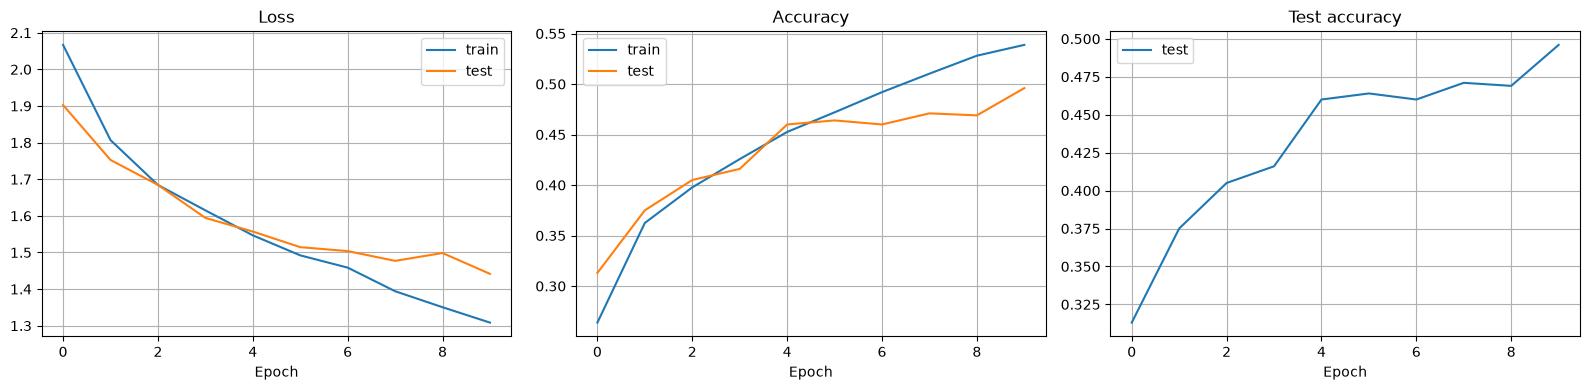

In [6]:
# 10-epoch baseline with history + plots
history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

def _train_epoch(epoch):
    model.train()
    criterion = nn.CrossEntropyLoss()
    running_loss, correct, total = 0.0, 0, 0
    for data, target in train_loader:
        if cuda:
            data, target = data.cuda(), target.cuda()
        optimizer.zero_grad()
        logits, _ = model(data)
        loss = criterion(logits, target)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        correct += (logits.argmax(1) == target).sum().item()
        total += target.size(0)
    return running_loss / len(train_loader), correct / total

def _test_epoch():
    model.eval()
    criterion = nn.CrossEntropyLoss()
    test_loss, correct = 0.0, 0
    with torch.no_grad():
        for data, target in test_loader:
            if cuda:
                data, target = data.cuda(), target.cuda()
            logits, _ = model(data)
            test_loss += criterion(logits, target).item()
            correct += (logits.argmax(1) == target).sum().item()
    return test_loss / len(test_loader), correct / len(test_loader.dataset)

# (model + optimizer were already created in the LeNet5 cell — reuse them)
for epoch in range(1, epochs + 1):
    trl, tra = _train_epoch(epoch)
    tel, tea = _test_epoch()
    history['train_loss'].append(trl)
    history['train_acc'].append(tra)
    history['test_loss'].append(tel)
    history['test_acc'].append(tea)
    writer.add_scalar('Loss/train', trl, epoch)
    writer.add_scalar('Accuracy/train', tra, epoch)
    writer.add_scalar('Loss/test', tel, epoch)
    writer.add_scalar('Accuracy/test', tea, epoch)
    print(f"Epoch {epoch}: train_loss={trl:.4f}, train_acc={tra:.4f} | "
          f"test_loss={tel:.4f}, test_acc={tea:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['test_loss'], label='test')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True)
axes[1].plot(history['train_acc'], label='train')
axes[1].plot(history['test_acc'], label='test')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True)
axes[2].plot(history['test_acc'], label='test')
axes[2].set_title('Test accuracy'); axes[2].set_xlabel('Epoch'); axes[2].legend(); axes[2].grid(True)
plt.tight_layout(); plt.show()

### 1(b) Baseline — observations

With the default configuration (Adam, lr = 1e-3, batch size 128, 10 epochs) the network reached 49.6% test accuracy and 53.9% train accuracy. Both train and test losses decrease overall, although test loss ticks up slightly at epoch 9 (1.4771 → 1.4985). Train and test accuracy track closely through epoch 6, but the final gap is about 4.3 percentage points, so the model is still underfitting / not fully converged rather than strongly overfitting. More epochs or higher capacity would likely help.

**Note on one-hot labels.** `nn.CrossEntropyLoss` fuses `log_softmax` and
negative-log-likelihood and expects integer class indices; this is numerically
equivalent to one-hot labels + `softmax` + `NLLLoss`, but more stable. The
one-hot demonstration above shows the one-hot representation for completeness;
the training code uses the equivalent fused formulation.

conv1 weight shape: (6, 1, 5, 5)


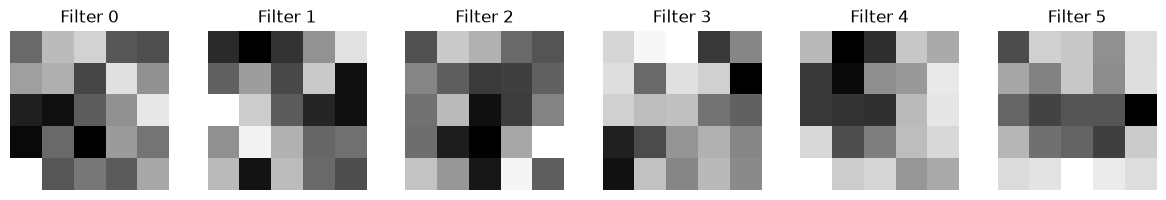

In [7]:
weights = model.features[0].weight.data.cpu().numpy()
print("conv1 weight shape:", weights.shape)

fig, axes = plt.subplots(1, weights.shape[0], figsize=(12, 2))
for i in range(weights.shape[0]):
    axes[i].imshow(weights[i, 0], cmap='gray')
    axes[i].set_title(f'Filter {i}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

conv1: shape=(128, 6, 28, 28), mean=-0.0138, std=0.3262
conv1 per-filter mean: [-0.214  0.044 -0.053  0.004  0.02   0.116]
conv1 per-filter std : [0.221 0.228 0.39  0.337 0.405 0.213]


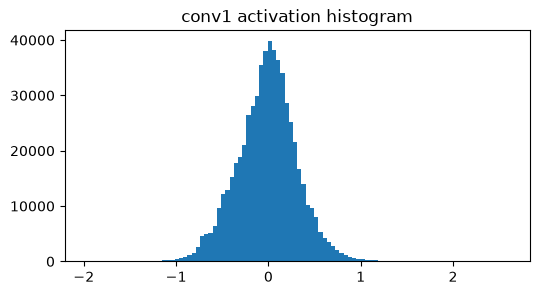

conv2: shape=(128, 16, 10, 10), mean=-0.2096, std=0.4435
conv2 per-filter mean: [-0.28  -0.151 -0.157 -0.166 -0.189 -0.132 -0.251 -0.089 -0.187 -0.034
 -0.081 -0.48  -0.342 -0.383 -0.241 -0.191]
conv2 per-filter std : [0.409 0.546 0.312 0.366 0.506 0.385 0.426 0.294 0.286 0.376 0.347 0.643
 0.468 0.451 0.457 0.427]


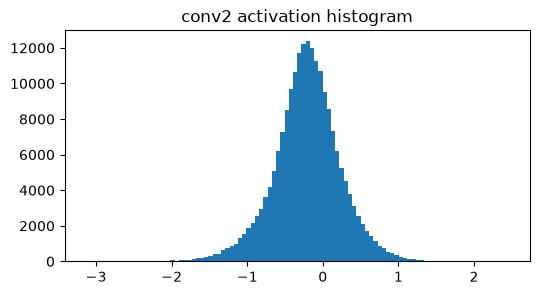

In [8]:
# ===== Activations + per-filter statistics =====
model.eval()
data, target = next(iter(test_loader))
if cuda:
    data = data.cuda()

with torch.no_grad():
    x = model.features[0](data)   # conv1
    x = model.features[1](x)      # tanh
    x = model.features[2](x)      # pool
    conv1_out = model.features[0](data)
    conv2_out = model.features[3](x)

for name, act in [("conv1", conv1_out), ("conv2", conv2_out)]:
    a = act.cpu().numpy()
    print(f"{name}: shape={a.shape}, mean={a.mean():.4f}, std={a.std():.4f}")
    print(f"{name} per-filter mean:", np.round(a.mean(axis=(0, 2, 3)), 3))
    print(f"{name} per-filter std :", np.round(a.std(axis=(0, 2, 3)), 3))
    writer.add_histogram(f'activations/{name}', a, 0)
    plt.figure(figsize=(6, 3))
    plt.hist(a.ravel(), bins=100)
    plt.title(f'{name} activation histogram')
    plt.show()

### 1(c) Filter and activation observations

The six 5×5 first-layer kernels show oriented edge / Gabor-like patterns:
some respond to horizontal edges, others to vertical or diagonal edges, and
some act as center-surround blob detectors. Different filters also exhibit
different spatial frequencies and opposite polarity (light-on-dark versus
dark-on-light). This is exactly the classical "bank of edge detectors" that
is expected from the first layer of a CNN trained on natural images.

On the test set, conv1 activations have mean ≈ −0.014 and std ≈ 0.326, while conv2 activations have mean ≈ −0.210 and std ≈ 0.444. The histograms are unimodal and roughly centred near zero, with heavier tails in conv2, indicating that deeper features are sparser and have a larger dynamic range.

In [9]:
def make_cifar_loaders(bs):
    tr = DataLoader(train_dataset, batch_size=bs, shuffle=True, num_workers=0)
    te = DataLoader(test_dataset, batch_size=bs, shuffle=False, num_workers=0)
    return tr, te

def run_cifar_experiment(lr=0.001, bs=128, opt_name='Adam', n_epochs=3, tag=None):
    tr_loader, te_loader = make_cifar_loaders(bs)
    m = LeNet5(num_classes=10, grayscale=True)
    if cuda:
        m.cuda()

    if opt_name == 'Adam':
        opt = optim.Adam(m.parameters(), lr=lr)
    elif opt_name == 'SGD':
        opt = optim.SGD(m.parameters(), lr=lr, momentum=0.9)
    else:
        raise ValueError(opt_name)

    criterion = nn.CrossEntropyLoss()
    if tag is None:
        tag = f'{opt_name}_lr{lr}_bs{bs}'

    hist = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

    for epoch in range(1, n_epochs + 1):
        m.train()
        running_loss, correct, total = 0.0, 0, 0
        for data, target in tr_loader:
            if cuda:
                data, target = data.cuda(), target.cuda()
            opt.zero_grad()
            logits, _ = m(data)
            loss = criterion(logits, target)
            loss.backward()
            opt.step()
            running_loss += loss.item()
            correct += (logits.argmax(1) == target).sum().item()
            total += target.size(0)
        train_loss = running_loss / len(tr_loader)
        train_acc = correct / total

        m.eval()
        te_loss, te_correct = 0.0, 0
        with torch.no_grad():
            for data, target in te_loader:
                if cuda:
                    data, target = data.cuda(), target.cuda()
                logits, _ = m(data)
                te_loss += criterion(logits, target).item()
                te_correct += (logits.argmax(1) == target).sum().item()
        te_loss /= len(te_loader)
        te_acc = te_correct / len(te_loader.dataset)

        hist['train_loss'].append(train_loss)
        hist['train_acc'].append(train_acc)
        hist['test_loss'].append(te_loss)
        hist['test_acc'].append(te_acc)

        writer.add_scalar(f'{tag}/Loss/train', train_loss, epoch)
        writer.add_scalar(f'{tag}/Accuracy/train', train_acc, epoch)
        writer.add_scalar(f'{tag}/Loss/test', te_loss, epoch)
        writer.add_scalar(f'{tag}/Accuracy/test', te_acc, epoch)
        print(f"{tag} epoch {epoch}: train_acc={train_acc:.4f}, test_acc={te_acc:.4f}")

    return hist

Adam lr=1e-3 epoch 1: train_acc=0.2757, test_acc=0.3390
Adam lr=1e-3 epoch 2: train_acc=0.3729, test_acc=0.3920
Adam lr=1e-3 epoch 3: train_acc=0.4149, test_acc=0.4370
Adam lr=1e-2 epoch 1: train_acc=0.2870, test_acc=0.3730
Adam lr=1e-2 epoch 2: train_acc=0.3916, test_acc=0.3930
Adam lr=1e-2 epoch 3: train_acc=0.4542, test_acc=0.3830
Adam lr=1e-4 epoch 1: train_acc=0.1547, test_acc=0.2150
Adam lr=1e-4 epoch 2: train_acc=0.2229, test_acc=0.2410
Adam lr=1e-4 epoch 3: train_acc=0.2614, test_acc=0.2730
SGD lr=1e-2 m=0.9 epoch 1: train_acc=0.1689, test_acc=0.2410
SGD lr=1e-2 m=0.9 epoch 2: train_acc=0.2462, test_acc=0.2940
SGD lr=1e-2 m=0.9 epoch 3: train_acc=0.3071, test_acc=0.3250


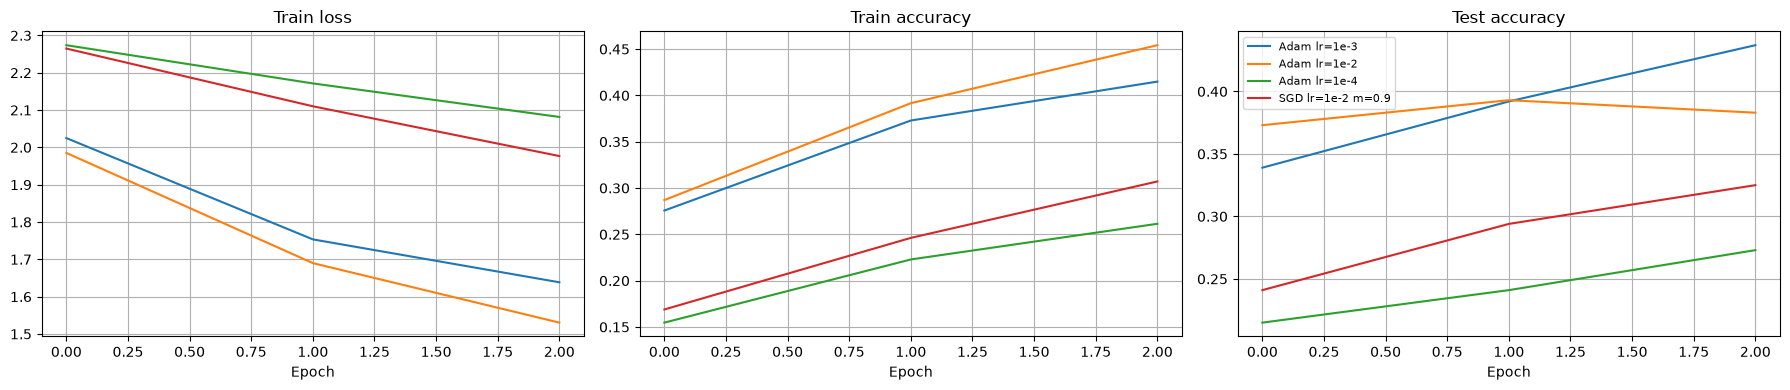

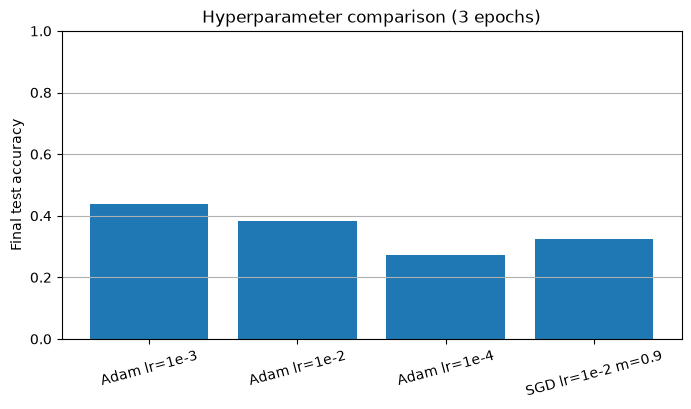


Final test accuracies:
Adam lr=1e-3: 0.4370
Adam lr=1e-2: 0.3830
Adam lr=1e-4: 0.2730
SGD lr=1e-2 m=0.9: 0.3250


In [10]:
configs = [
    dict(lr=0.001,  bs=128, opt_name='Adam', n_epochs=3, tag='Adam lr=1e-3'),
    dict(lr=0.01,   bs=128, opt_name='Adam', n_epochs=3, tag='Adam lr=1e-2'),
    dict(lr=0.0001, bs=128, opt_name='Adam', n_epochs=3, tag='Adam lr=1e-4'),
    dict(lr=0.01,   bs=128, opt_name='SGD',  n_epochs=3, tag='SGD lr=1e-2 m=0.9'),
]

histories = {}
for cfg in configs:
    histories[cfg['tag']] = run_cifar_experiment(**cfg)

# Comparison curves
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for tag, h in histories.items():
    axes[0].plot(h['train_loss'], label=tag)
    axes[1].plot(h['train_acc'], label=tag)
    axes[2].plot(h['test_acc'], label=tag)
axes[0].set_title('Train loss'); axes[0].set_xlabel('Epoch'); axes[0].grid(True)
axes[1].set_title('Train accuracy'); axes[1].set_xlabel('Epoch'); axes[1].grid(True)
axes[2].set_title('Test accuracy'); axes[2].set_xlabel('Epoch'); axes[2].grid(True)
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Bar chart of final accuracies
tags = list(histories.keys())
final = [histories[t]['test_acc'][-1] for t in tags]
plt.figure(figsize=(8, 4))
plt.bar(tags, final)
plt.ylabel('Final test accuracy')
plt.title('Hyperparameter comparison (3 epochs)')
plt.xticks(rotation=15); plt.ylim(0, 1); plt.grid(axis='y')
plt.show()

print("\nFinal test accuracies:")
for t, h in histories.items():
    print(f"{t}: {h['test_acc'][-1]:.4f}")

### 1(b) Hyperparameter search — observations

Four configurations were compared for 3 epochs each: Adam with lr = 1e-3, 1e-2, and 1e-4, and SGD with momentum 0.9 and lr = 1e-2. Adam with lr = 1e-3 achieved the best final test accuracy (43.7%), followed by Adam lr = 1e-2 (38.3%), SGD with momentum (32.5%) and Adam lr = 1e-4 (27.3%).

A learning rate that is too small (1e-4) converges too slowly within a short budget. Adam lr = 1e-2 reached a higher train accuracy by epoch 3 (45.4%) but a lower test accuracy (38.3%), suggesting less stable generalization in this short run. SGD with momentum needs more epochs or tuning to match Adam. The 10-epoch baseline at Adam lr = 1e-3 reached 49.6% test accuracy.

In [11]:
# ===== CELL 10 =====
writer.close()

---

# Section B — Problem 2
## Visualizing and Understanding Convolutional Networks (Zeiler & Fergus, 2014)

## 2. Summary of "Visualizing and Understanding Convolutional Networks"
### (Zeiler & Fergus, ECCV 2014)

The paper asks a simple but important question: what do convolutional networks
actually learn, and can we use that understanding to build better models? The
authors introduce a multi-faceted visualisation framework and use it both as a
diagnostic and as a guide for architecture design.

**(1) Deconvolutional feature visualisation.** They attach a "deconvnet" to any
convolutional layer. Given an activation map, the deconvnet performs unpooling
(using the arg-max "switch" locations recorded during the forward max-pooling
pass), rectification (ReLU), and transposed convolution with the same filters,
mapping the activation back to input-pixel space. The resulting image shows the
pattern that maximally excites a given unit. The visualisations reveal a clear
hierarchy: layer 1–2 units detect edges, colours and simple textures; layer 3
captures more complex textures and object parts; layers 4–5 encode whole object
parts and entire objects with pose variation. The analysis also exposes dead
filters and aliasing artefacts caused by large strides.

**(2) Occlusion sensitivity.** A grey square is slid over the input image and
the drop in the correct-class score is recorded, producing a heat map of which
image regions the model relies on. The heat maps show that the network localises
objects rather than relying on background context, and they can even be used for
weakly-supervised localisation.

**(3) Feature evolution during training.** Running the deconvnet at different
epochs shows that lower layers converge within a few epochs (generic edges),
while higher layers need many epochs to become class-specific. This explains
why fine-tuning only the top layers is often sufficient.

**(4) Architecture insights.** Motivated by the visualisations, they replace
the 11×11 stride-4 first-layer filters with 7×7 stride-2 filters, increase the
number of feature maps, add a sixth convolutional layer, and reduce stride
elsewhere. These changes improved ImageNet 2012 top-5 error from 16.4%
(Krizhevsky et al.) to 14.8%, and the resulting features transferred well to
Caltech-256, Caltech-101 and PASCAL VOC, achieving state-of-the-art results at
the time.

**(5) Ablations.** Clamping high-activation features, removing layers, or
perturbing filters degrades accuracy in a way that correlates with the
visualisations, confirming that the visualised features are genuinely used by
the classifier.

**Key takeaway.** Visualisation is not merely cosmetic: deconvnet feature maps
and occlusion heat maps provide actionable insight into what a CNN has learned,
how features evolve during training, and where the architecture can be improved.

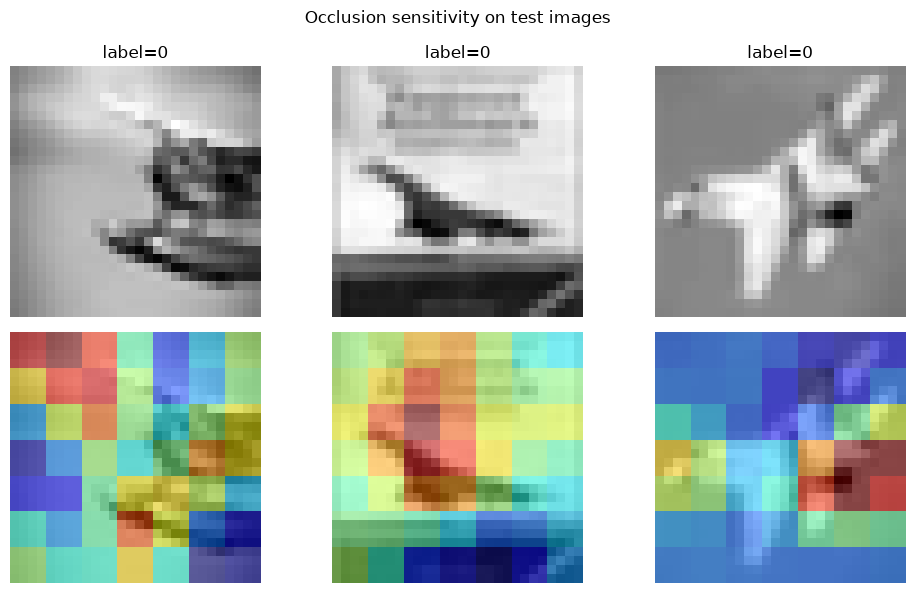

In [12]:
# Optional: occlusion sensitivity on test images (Zeiler & Fergus)
def occlusion_heatmap(model, img, label, patch=8, stride=4):
    model.eval()
    H, W = img.shape[-2:]
    heat = np.zeros((H, W)); counts = np.zeros((H, W))
    inp = img.unsqueeze(0)
    if cuda: inp = inp.cuda()
    with torch.no_grad():
        base = F.softmax(model(inp)[0], 1)[0, label].item()
        for i in range(0, H - patch + 1, stride):
            for j in range(0, W - patch + 1, stride):
                occ = img.clone()
                occ[:, i:i+patch, j:j+patch] = 0.0
                o = occ.unsqueeze(0)
                if cuda: o = o.cuda()
                p = F.softmax(model(o)[0], 1)[0, label].item()
                heat[i:i+patch, j:j+patch] += (base - p)
                counts[i:i+patch, j:j+patch] += 1
    return heat / np.maximum(counts, 1)

model.eval()
imgs, labels = next(iter(test_loader))
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for k in range(3):
    img, lab = imgs[k], labels[k].item()
    hm = occlusion_heatmap(model, img, lab)
    axes[0, k].imshow(img[0].cpu(), cmap='gray')
    axes[0, k].set_title(f'label={lab}'); axes[0, k].axis('off')
    axes[1, k].imshow(img[0].cpu(), cmap='gray')
    axes[1, k].imshow(hm, cmap='jet', alpha=0.5); axes[1, k].axis('off')
plt.suptitle('Occlusion sensitivity on test images')
plt.tight_layout(); plt.show()